In [1]:
import pandas as pd
import numpy as np
# Chargement du fichier CSV
data = pd.read_csv("mnist_784.csv")
print(data.head())

# Supprimer les lignes contenant des valeurs manquantes
n_before = len(data)
data = data.dropna()
print("Lignes incompletes supprimees :", n_before - len(data))
# Séparer les caractéristiques et les étiquettes
X = data.drop("class", axis=1).values
y = data["class"].astype(int).values

# Verifier la structure attendue pour MNIST
assert X.shape[1] == 784, "Chaque image doit contenir 784 pixels"
assert np.isfinite(X).all(), "Pixels non numeriques detectes"
assert X.min() >= 0 and X.max() <= 255, "Pixels hors de [0, 255]"
# Normalisation des niveaux de gris
X = X / 255.0

   pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
0       0       0       0       0       0       0       0       0       0   
1       0       0       0       0       0       0       0       0       0   
2       0       0       0       0       0       0       0       0       0   
3       0       0       0       0       0       0       0       0       0   
4       0       0       0       0       0       0       0       0       0   

   pixel10  ...  pixel776  pixel777  pixel778  pixel779  pixel780  pixel781  \
0        0  ...         0         0         0         0         0         0   
1        0  ...         0         0         0         0         0         0   
2        0  ...         0         0         0         0         0         0   
3        0  ...         0         0         0         0         0         0   
4        0  ...         0         0         0         0         0         0   

   pixel782  pixel783  pixel784  class  
0         0         0

In [3]:
print("Dimensions de X :", X.shape)
print("Min et Max :", X.min(), X.max())
print("Classes :", np.unique(y))

Dimensions de X : (70000, 784)
Min et Max : 0.0 1.0
Classes : [0 1 2 3 4 5 6 7 8 9]


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, stratify=y, random_state=42
)

mlp = MLPClassifier(
hidden_layer_sizes=(50, 20, 10),
activation="relu",
solver="adam",
learning_rate_init=0.001,
max_iter=100,
random_state=42
)

mlp.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(50, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",100
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [5]:
from sklearn.metrics import accuracy_score, classification_report

y_train_pred = mlp.predict(X_train)
y_test_pred = mlp.predict(X_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
print("Accuracy apprentissage :", train_acc)
print("Accuracy test :", test_acc)
print(classification_report(y_test, y_test_pred))

Accuracy apprentissage : 1.0
Accuracy test : 0.9688571428571429
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1381
           1       0.98      0.99      0.98      1575
           2       0.97      0.97      0.97      1398
           3       0.97      0.96      0.97      1428
           4       0.97      0.96      0.96      1365
           5       0.97      0.96      0.96      1263
           6       0.97      0.98      0.98      1375
           7       0.97      0.97      0.97      1459
           8       0.96      0.96      0.96      1365
           9       0.95      0.96      0.95      1391

    accuracy                           0.97     14000
   macro avg       0.97      0.97      0.97     14000
weighted avg       0.97      0.97      0.97     14000



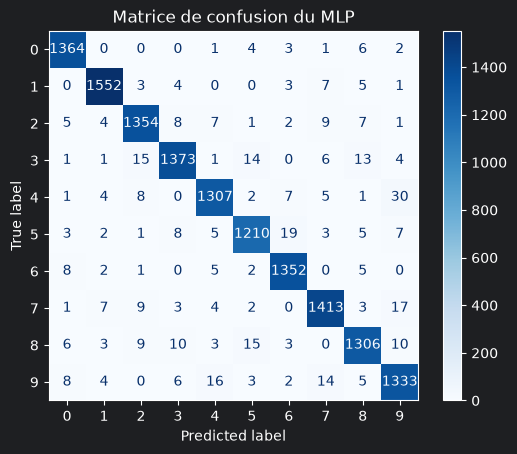

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
y_test, y_test_pred, cmap="Blues", values_format="d"
)
plt.title("Matrice de confusion du MLP")
plt.show()

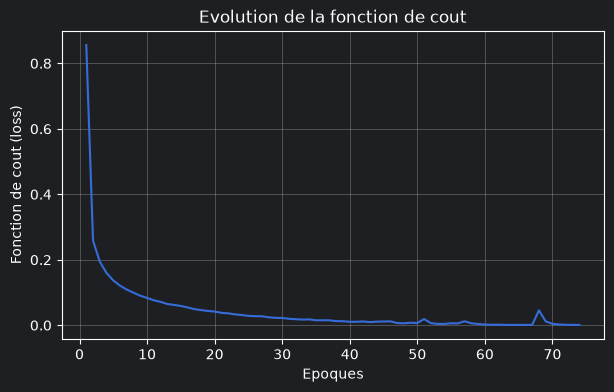

In [7]:
plt.figure(figsize=(7, 4))
epochs = np.arange(1, len(mlp.loss_curve_) + 1)
plt.plot(epochs, mlp.loss_curve_)
plt.xlabel("Epoques")
plt.ylabel("Fonction de cout (loss)")
plt.title("Evolution de la fonction de cout")
plt.grid(True)
plt.show()

In [8]:
for i, w in enumerate(mlp.coefs_):
 print(f"Poids {i + 1} : {w.shape}")

for i, b in enumerate(mlp.intercepts_):
 print(f"Biais {i + 1} : {b.shape}")

n_params = sum(w.size for w in mlp.coefs_) + \
sum(b.size for b in mlp.intercepts_)
print("Nombre total de parametres :", n_params)

Poids 1 : (784, 50)
Poids 2 : (50, 20)
Poids 3 : (20, 10)
Poids 4 : (10, 10)
Biais 1 : (50,)
Biais 2 : (20,)
Biais 3 : (10,)
Biais 4 : (10,)
Nombre total de parametres : 40590


In [11]:
from sklearn.model_selection import (
 train_test_split, StratifiedKFold, cross_val_score
)

# Sous-ensemble pour les experimentations
X_cv, _, y_cv, _ = train_test_split(
 X_train, y_train, train_size=6000,
 stratify=y_train, random_state=42
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

scores = cross_val_score(
 MLPClassifier(
 hidden_layer_sizes=(50, 20, 10),
 learning_rate_init=0.001,
 max_iter=100,
 random_state=42
),
    X_cv, y_cv, cv=cv, scoring="accuracy", n_jobs=1
)
print("Accuracies :", scores)
print("Moyenne :", scores.mean())
print("Ecart-type :", scores.std())
baseline_cv = scores.mean()

C:\Users\user\PycharmProjects\Tps_AI\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\user\PycharmProjects\Tps_AI\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracies : [0.9225 0.92   0.9145]
Moyenne : 0.919
Ecart-type : 0.0033416562759605787


In [12]:
from sklearn.model_selection import GridSearchCV

param_grid = {
  "hidden_layer_sizes": [(50,), (50, 20), (50, 20, 10)],
  "activation": ["relu", "tanh"],
  "learning_rate_init": [0.001, 0.01]
}

In [13]:
search = GridSearchCV(
 estimator=MLPClassifier(
 max_iter=100, solver="adam", random_state=42
),
 param_grid=param_grid,
 scoring="accuracy",
 cv=cv,
 n_jobs=1,
 refit=True
)
search.fit(X_cv, y_cv)

print("Meilleurs parametres :", search.best_params_)
print("Meilleure accuracy CV :", search.best_score_)
print("Accuracy CV du MLP initial :", baseline_cv)
print("Gain CV (points) :", 100 * (search.best_score_ - baseline_cv))

C:\Users\user\PycharmProjects\Tps_AI\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\user\PycharmProjects\Tps_AI\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\user\PycharmProjects\Tps_AI\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\user\PycharmProjects\Tps_AI\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Meilleurs parametres : {'activation': 'relu', 'hidden_layer_sizes': (50, 20), 'learning_rate_init': 0.01}
Meilleure accuracy CV : 0.9315000000000001
Accuracy CV du MLP initial : 0.919
Gain CV (points) : 1.2500000000000067


In [14]:
# Reentrainement sur l’ensemble d’apprentissage complet
best_mlp = MLPClassifier(
 **search.best_params_,
 max_iter=100, solver="adam", random_state=42
)

best_mlp.fit(X_train, y_train)
print("Accuracy test (modele optimise) :",
best_mlp.score(X_test, y_test))
print("Accuracy test (modele initial) :", test_acc)

Accuracy test (modele optimise) : 0.966
Accuracy test (modele initial) : 0.9688571428571429
